PySpark Environment Setup & Data Ingestion

In [ ]:
# 1. Install dependencies
!pip install pyspark matplotlib seaborn scikit-learn

import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, DecisionTreeRegressor
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, LinearSVC, NaiveBayes
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import RegressionEvaluator, MulticlassClassificationEvaluator, ClusteringEvaluator
from sklearn.metrics import confusion_matrix

# 2. Initialize Spark Session
spark = SparkSession.builder \
    .appName("PySpark_Heart_Disease_Analytics") \
    .master("local[*]") \
    .getOrCreate()

print("Spark Session Active. Version:", spark.version)

# 3. Direct Download UCI Heart Disease Cleveland Dataset from public GitHub mirror
url = "https://raw.githubusercontent.com/sharmaroshan/Heart-UCI-Dataset/master/heart.csv"
urllib.request.urlretrieve(url, "heart.csv")

# 4. Read dataset into PySpark DataFrame
df = spark.read.csv("heart.csv", header=True, inferSchema=True)
df.show(5)
df.printSchema()

Spark Session Active. Version: 4.0.4
+---+---+---+--------+----+---+-------+-------+-----+-------+-----+---+----+------+
|age|sex| cp|trestbps|chol|fbs|restecg|thalach|exang|oldpeak|slope| ca|thal|target|
+---+---+---+--------+----+---+-------+-------+-----+-------+-----+---+----+------+
| 63|  1|  3|     145| 233|  1|      0|    150|    0|    2.3|    0|  0|   1|     1|
| 37|  1|  2|     130| 250|  0|      1|    187|    0|    3.5|    0|  0|   2|     1|
| 41|  0|  1|     130| 204|  0|      0|    172|    0|    1.4|    2|  0|   2|     1|
| 56|  1|  1|     120| 236|  0|      1|    178|    0|    0.8|    2|  0|   2|     1|
| 57|  0|  0|     120| 354|  0|      1|    163|    1|    0.6|    2|  0|   2|     1|
+---+---+---+--------+----+---+-------+-------+-----+-------+-----+---+----+------+
only showing top 5 rows
root
 |-- age: integer (nullable = true)
 |-- sex: integer (nullable = true)
 |-- cp: integer (nullable = true)
 |-- trestbps: integer (nullable = true)
 |-- chol: integer (nullable =

Exploratory Data Analysis & Correlation Heatmap

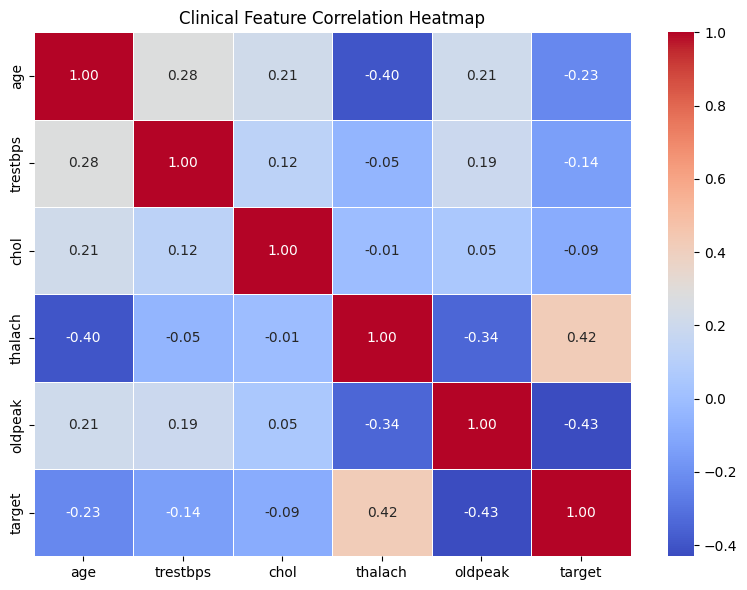

In [ ]:
# Select key numerical/clinical attributes for correlation analysis
corr_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'target']
pandas_df = df.select(corr_cols).toPandas()

# Plot Seaborn Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(pandas_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Clinical Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

Spark ML Key Concepts (Vectorization & Standard Scaling)

In [ ]:
# List of input feature columns
feature_cols = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

# A. VectorAssembler (Transformer)
assembler = VectorAssembler(inputCols=feature_cols, outputCol="unscaled_features")
df_assembled = assembler.transform(df)

# B. StandardScaler (Estimator -> Transformer)
scaler = StandardScaler(inputCol="unscaled_features", outputCol="features", withStd=True, withMean=True)
scaler_model = scaler.fit(df_assembled)
data = scaler_model.transform(df_assembled)

# C. Train/Test Split (80/20)
train_data, test_data = data.randomSplit([0.8, 0.2], seed=42)
print(f"Training Samples: {train_data.count()}, Testing Samples: {test_data.count()}")

Training Samples: 256, Testing Samples: 47


Regression Models (Predicting Max Heart Rate thalach)

In [ ]:
# Prepare features for regression (all clinical features except target thalach)
reg_features = [c for c in feature_cols if c != 'thalach']
reg_assembler = VectorAssembler(inputCols=reg_features, outputCol="reg_unscaled")
reg_df = reg_assembler.transform(df)

reg_scaler = StandardScaler(inputCol="reg_unscaled", outputCol="reg_features", withStd=True, withMean=True)
reg_data = reg_scaler.fit(reg_df).transform(reg_df)

reg_train, reg_test = reg_data.randomSplit([0.8, 0.2], seed=42)

# --- 1. Linear Regression ---
lr = LinearRegression(featuresCol="reg_features", labelCol="thalach")
lr_model = lr.fit(reg_train)
lr_preds = lr_model.transform(reg_test)

# --- 2. Decision Tree Regressor ---
dt_reg = DecisionTreeRegressor(featuresCol="reg_features", labelCol="thalach")
dt_reg_model = dt_reg.fit(reg_train)
dt_reg_preds = dt_reg_model.transform(reg_test)

# Evaluators
eval_r2 = RegressionEvaluator(labelCol="thalach", predictionCol="prediction", metricName="r2")
eval_rmse = RegressionEvaluator(labelCol="thalach", predictionCol="prediction", metricName="rmse")
eval_mae = RegressionEvaluator(labelCol="thalach", predictionCol="prediction", metricName="mae")

print("================ REGRESSION PERFORMANCE METRICS ================")
print(f"Linear Regression    -> R2: {eval_r2.evaluate(lr_preds):.4f} | RMSE: {eval_rmse.evaluate(lr_preds):.4f} | MAE: {eval_mae.evaluate(lr_preds):.4f}")
print(f"Decision Tree Reg.   -> R2: {eval_r2.evaluate(dt_reg_preds):.4f} | RMSE: {eval_rmse.evaluate(dt_reg_preds):.4f} | MAE: {eval_mae.evaluate(dt_reg_preds):.4f}")

================ REGRESSION PERFORMANCE METRICS ================
Linear Regression    -> R2: 0.3348 | RMSE: 17.6491 | MAE: 13.3468
Decision Tree Reg.   -> R2: 0.1025 | RMSE: 20.5003 | MAE: 14.5785


Classification Algorithms & Confusion Matrices


Classifier: Logistic Regression (Accuracy: 85.11%)


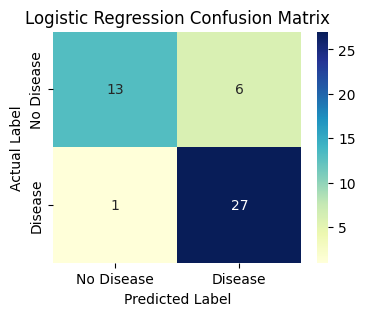


Classifier: Decision Tree (Accuracy: 82.98%)


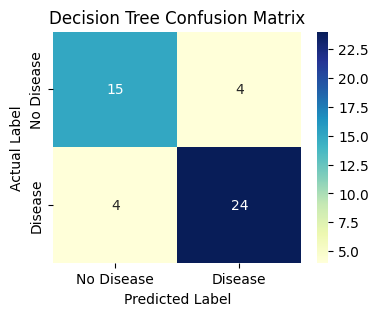


Classifier: Linear SVM (Accuracy: 85.11%)


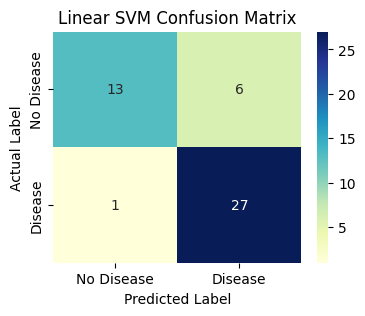


Classifier: Naive Bayes (Accuracy: 74.47%)


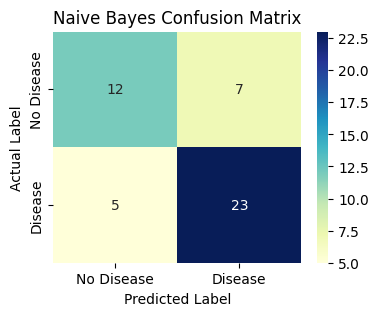

In [ ]:
# Setup Classification Algorithms
classifiers = {
    "Logistic Regression": LogisticRegression(featuresCol="features", labelCol="target"),
    "Decision Tree": DecisionTreeClassifier(featuresCol="features", labelCol="target"),
    "Linear SVM": LinearSVC(featuresCol="features", labelCol="target"),
    # Naive Bayes requires non-negative raw values
    "Naive Bayes": NaiveBayes(featuresCol="unscaled_features", labelCol="target")
}

# Run Classifiers & Draw Confusion Matrices
for name, clf in classifiers.items():
    model = clf.fit(train_data)
    preds = model.transform(test_data)

    # Calculate Accuracy
    evaluator = MulticlassClassificationEvaluator(labelCol="target", predictionCol="prediction", metricName="accuracy")
    accuracy = evaluator.evaluate(preds)

    # Extract Predictions for Confusion Matrix
    y_true = preds.select("target").toPandas()
    y_pred = preds.select("prediction").toPandas()
    cm = confusion_matrix(y_true, y_pred)

    # Display Results & Heatmap
    print(f"\nClassifier: {name} (Accuracy: {accuracy*100:.2f}%)")
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.show()

Unsupervised Learning (K-Means Clustering)

In [ ]:
# Fit K-Means Model (k=3 Clusters)
kmeans = KMeans(featuresCol="features", k=3, seed=42)
km_model = kmeans.fit(data)
km_predictions = km_model.transform(data)

# Evaluate Silhouette Score
evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="prediction")
silhouette = evaluator.evaluate(km_predictions)

print(f"K-Means Clustering Silhouette Score: {silhouette:.4f}")

# Show sample cluster assignments
km_predictions.select("age", "trestbps", "chol", "thalach", "prediction").show(5)

K-Means Clustering Silhouette Score: 0.2129
+---+--------+----+-------+----------+
|age|trestbps|chol|thalach|prediction|
+---+--------+----+-------+----------+
| 63|     145| 233|    150|         0|
| 37|     130| 250|    187|         1|
| 41|     130| 204|    172|         1|
| 56|     120| 236|    178|         1|
| 57|     120| 354|    163|         1|
+---+--------+----+-------+----------+
only showing top 5 rows
